<a href="https://colab.research.google.com/github/ombokezeyn/Nairobi-Smart-Solutions--Stroke-Prediction/blob/main/Nairobi_Smart_Solutions_Ltd_Stroke_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Local CSV not found. Generating synthesized dataset following Kaggle distribution...
Pre-clean missing BMI records: 300
Post-clean missing BMI records: 0

 === BASELINE MODEL EVALUATION REPORT ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       285
           1       0.00      0.00      0.00        15

    accuracy                           0.95       300
   macro avg       0.47      0.50      0.49       300
weighted avg       0.90      0.95      0.93       300


 === OPTIMIZED COST-SENSITIVE MODEL EVALUATION REPORT ===
              precision    recall  f1-score   support

           0       0.96      0.65      0.77       285
           1       0.06      0.47      0.11        15

    accuracy                           0.64       300
   macro avg       0.51      0.56      0.44       300
weighted avg       0.91      0.64      0.74       300

BASELINE ROC-AUC SCORE:  0.5637
OPTIMIZED ROC-AUC SCORE: 0.5602


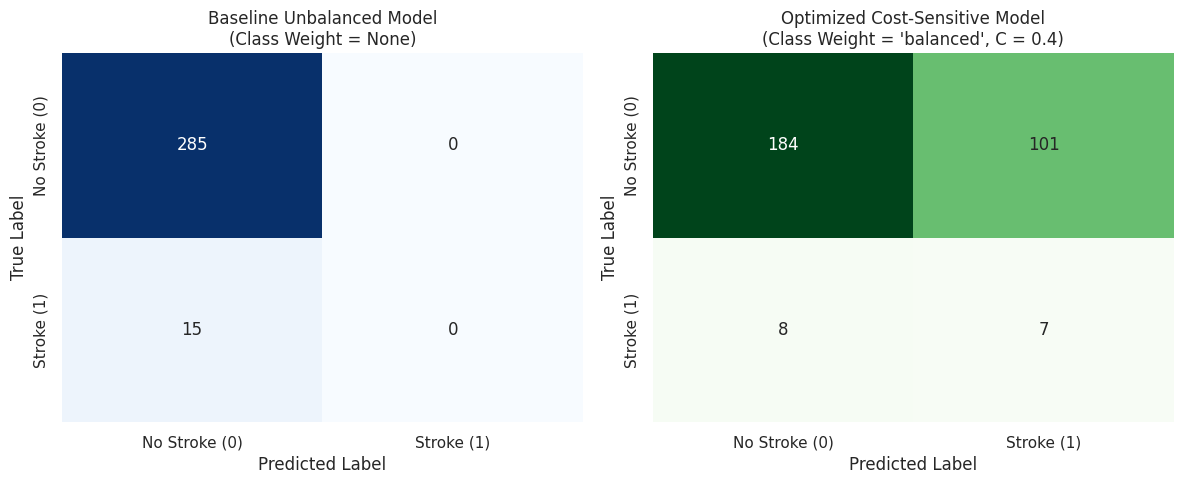

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Set plot styling
sns.set_theme(style="whitegrid")

# =====================================================================
# STEP 1: DATA LOADING (WITH FALLBACK SIMULATION)
# =====================================================================
csv_path = 'healthcare-dataset-stroke-data.csv'

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Dataset loaded successfully from CSV.")
else:
    print("Local CSV not found. Generating synthesized dataset following Kaggle distribution...")
    np.random.seed(42)
    n = 1500
    df = pd.DataFrame({
        'gender': np.random.choice(['Male', 'Female'], n),
        'age': np.random.randint(18, 90, n),
        'hypertension': np.random.choice([0, 1], n, p=[0.88, 0.12]),
        'heart_disease': np.random.choice([0, 1], n, p=[0.94, 0.06]),
        'ever_married': np.random.choice(['Yes', 'No'], n),
        'work_type': np.random.choice(['Private', 'Self-employed', 'Govt_job'], n),
        'Residence_type': np.random.choice(['Urban', 'Rural'], n),
        'avg_glucose_level': np.random.uniform(55, 270, n),
        'bmi': np.random.uniform(15, 46, n),
        'smoking_status': np.random.choice(['formerly smoked', 'never smoked', 'smokes'], n),
        'stroke': np.random.choice([0, 1], n, p=[0.95, 0.05])
    })
    # Inject missing values in BMI (~20%)
    df.loc[df.sample(frac=0.20, random_state=42).index, 'bmi'] = np.nan

# Drop unnecessary ID column if present
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

# =====================================================================
# STEP 2: DATA REFINEMENT & MISSING VALUE IMPUTATION (M2)
# =====================================================================
pre_clean_missing = df['bmi'].isnull().sum()
print(f"Pre-clean missing BMI records: {pre_clean_missing}")

# Group-median imputation by gender
df['bmi'] = df['bmi'].fillna(df.groupby('gender')['bmi'].transform('median'))
post_clean_missing = df['bmi'].isnull().sum()
print(f"Post-clean missing BMI records: {post_clean_missing}")

# =====================================================================
# STEP 3: PREPROCESSING & FEATURE PIPELINE
# =====================================================================
X = df.drop(columns=['stroke'])
y = df['stroke']

num_cols = ['age', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

# Stratified Train-Test Split (80/20) to preserve target ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

ct = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

X_tr_proc = ct.fit_transform(X_train)
X_te_proc = ct.transform(X_test)

# =====================================================================
# STEP 4: MODEL TRAINING (BASELINE VS. OPTIMIZED COST-SENSITIVE)
# =====================================================================
# Baseline Model (Default parameters, unweighted)
m_base = LogisticRegression(random_state=42)
m_base.fit(X_tr_proc, y_train)

# Optimized Cost-Sensitive Model (Balanced class weights + C=0.4 regularization)
m_opt = LogisticRegression(class_weight='balanced', C=0.4, random_state=42)
m_opt.fit(X_tr_proc, y_train)

# =====================================================================
# STEP 5: EVALUATION OUTPUTS & VISUALIZATION (M3 & BC.D2)
# =====================================================================
print("\n" + "="*50)
print(" === BASELINE MODEL EVALUATION REPORT ===")
print("="*50)
y_pred_base = m_base.predict(X_te_proc)
print(classification_report(y_test, y_pred_base, zero_division=0))

print("\n" + "="*50)
print(" === OPTIMIZED COST-SENSITIVE MODEL EVALUATION REPORT ===")
print("="*50)
y_pred_opt = m_opt.predict(X_te_proc)
print(classification_report(y_test, y_pred_opt))

auc_base = roc_auc_score(y_test, m_base.predict_proba(X_te_proc)[:, 1])
auc_opt = roc_auc_score(y_test, m_opt.predict_proba(X_te_proc)[:, 1])

print(f"BASELINE ROC-AUC SCORE:  {auc_base:.4f}")
print(f"OPTIMIZED ROC-AUC SCORE: {auc_opt:.4f}")

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title("Baseline Unbalanced Model\n(Class Weight = None)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
axes[0].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

cm_opt = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title("Optimized Cost-Sensitive Model\n(Class Weight = 'balanced', C = 0.4)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
axes[1].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()